### Puxar base de dados

In [10]:
import pandas as pd

tabela = pd.read_csv(R'C:\Users\Usuario\Documents\GitHub\Codigos\Basico\19. Análise de Dados com o Pandas + Integração Python e Excel\Onde pegar exercícios de análise de dados- Kaggle\exportacoes_franca.csv')


### Informações Gerais

Quantas linhas têm a tabela? Existe algum valor vazio que deveria ser tratado?

In [ ]:
# ver as informação geral
tabela.info()


<class 'pandas.DataFrame'>
RangeIndex: 142360 entries, 0 to 142359
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   Year             142360 non-null  int64
 1   Month            142360 non-null  int64
 2   Country          142360 non-null  str  
 3   City             142360 non-null  str  
 4   SH4 Code         142360 non-null  int64
 5   SH4 Description  142360 non-null  str  
 6   SH2 Code         142360 non-null  int64
 7   SH2 Description  142360 non-null  str  
 8   Economic Block   142360 non-null  str  
 9   US$ FOB          142360 non-null  int64
 10  Net Weight       142360 non-null  int64
dtypes: int64(6), str(5)
memory usage: 11.9 MB


### Como foi a evolução das exportações para a frança ao longo dos anos?

Crie uma tabela com os anos de 2016, 2017, 2018, 2019 e 2020 e o valor US$ de exportações

,US$ FOB
Year,
2016,"US$ 4,615,500,082"
2017,"US$ 4,448,705,456"
2018,"US$ 5,239,424,416"
2019,"US$ 5,218,723,612"
2020,"US$ 3,967,594,810"


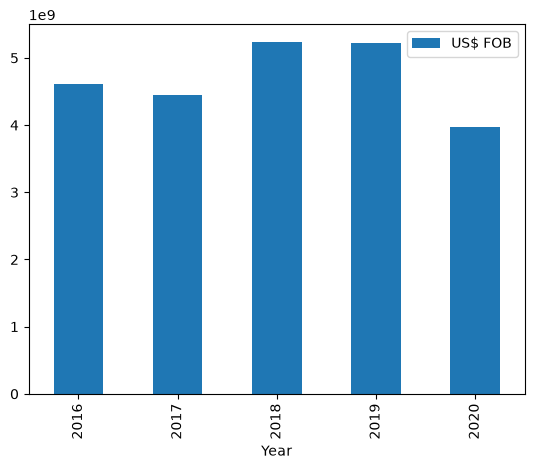

In [24]:
# agrupar  a tabela por "year" e US$ FOB
# para pegar os anos de 2016 a 2020

tabela_ano_exportacao = tabela[["Year","US$ FOB"]].groupby("Year").sum()


tabela_ano_exportacao.plot(kind="bar")

# vamos formata a tabela para ver melhor
def formatar(valor):
    valor_formatado = f"US$ {valor:,}"
    return valor_formatado

# aplicar a Formatação
tabela_ano_exportacao["US$ FOB"] = tabela_ano_exportacao['US$ FOB'].apply(formatar)

display(tabela_ano_exportacao)



### Quais os produtos mais exportados ao longo de todo o período?

Queremos saber os produtos com maior valor US$ de exportação

In [30]:
# agrupar a tabela por "SH2 Description" e US$ FOB
tabela_produtos_exportados = tabela[['SH2 Description','US$ FOB']].groupby("SH2 Description").sum()

# Colocando em orde decresente
tabela_produtos_exportados = tabela_produtos_exportados.sort_values(by="US$ FOB", ascending=False)

# aplicar a Formatação
tabela_produtos_exportados['US$ FOB'] = tabela_produtos_exportados['US$ FOB'].apply(formatar)

display(tabela_produtos_exportados)


,US$ FOB
SH2 Description,
Residues and waste from the food industries; others,"US$ 5,641,498,484"
"Ores, slag and ash","US$ 3,404,353,274"
"Nuclear reactors, boilers, machinery and mechanical appliances; others","US$ 1,889,781,694"
"Pulp of wood or of other fibrous cellulosic material, others,","US$ 1,855,424,642"
"Aircraft, spacecraft, and parts thereof","US$ 1,253,007,710"
...,...
"Umbrellas, sun umbrellas, walking-sticks, seat-sticks, whips, riding-crops, others","US$ 18,872"
Cork and articles of cork,"US$ 10,974"
"Wool, fine or coarse animal hair; horsehair yarn and woven fabric","US$ 2,540"


### Em 2020 qual cidade mais exportou para a França?
Em valores US$

In [45]:
# filtra tabela  para ano de "2020"
tabela_2020 = tabela.loc[tabela["Year"] == 2020, :] # linha e "2020" e a coluna e todas " : "

# agrupar a tabela por "City" e US$ FOB
tabela_cidade_2020 = tabela_2020[['City',"US$ FOB"]].groupby("City").sum()

# Colocando em orde decresente
# >>> tabela_cidade_2020 = tabela_cidade_2020.sort_values(by="US$ FOB", ascending=False)
tabela_cidade_2020 = tabela_cidade_2020[["US$ FOB"]].sort_values("US$ FOB", ascending=False)

# aplicar a Formatação
tabela_cidade_2020["US$ FOB"] = tabela_cidade_2020["US$ FOB"].apply(formatar)

display(tabela_cidade_2020)


,US$ FOB
City,
Duque de Caxias - RJ,"US$ 279,405,596"
Luís Eduardo Magalhães - BA,"US$ 265,328,132"
Ponta Grossa - PR,"US$ 187,777,016"
São José dos Campos - SP,"US$ 172,939,276"
Rio de Janeiro - RJ,"US$ 122,522,214"
...,...
Não-Me-Toque - RS,US$ 42
Cubatão - SP,US$ 40
Holambra - SP,US$ 10


### Quais os produtos mais exportados (em US$) que as 2 maiores cidades (em exportação em 2020) exportaram?

In [63]:
# indetificando a cidade
# Cidade = "Duque de Caxias - RJ" # localizar pelo nome
Cidade = tabela_cidade_2020.index[0] # localizar pelo .index

# filtra tabela para Cidade
tabela_cidade = tabela_2020.loc[tabela_2020["City"] == Cidade,:]

# agrupar a tabela por "produtos" e US$ FOB
tabela_produtos_cidade = tabela_cidade[['SH2 Description','US$ FOB']].groupby("SH2 Description").sum()

# Colocando em orde decresente
tabela_produtos_cidade = tabela_produtos_cidade[["US$ FOB"]].sort_values("US$ FOB", ascending=False)

# aplicar a Formatação
tabela_produtos_cidade["US$ FOB"] = tabela_produtos_cidade["US$ FOB"].apply(formatar)


print(f"Produtos mais exportados da cidade: {Cidade}")
print("---"*30)
print("---"*30)

display(tabela_produtos_cidade)

Produtos mais exportados da cidade: Duque de Caxias - RJ
------------------------------------------------------------------------------------------
------------------------------------------------------------------------------------------


,US$ FOB
SH2 Description,
"Nuclear reactors, boilers, machinery and mechanical appliances; others","US$ 185,816,982"
"Mineral fuels, mineral oils, bituminous substances; mineral waxes","US$ 67,355,688"
Articles of iron or steel,"US$ 9,118,714"
Residues and waste from the food industries; others,"US$ 4,014,274"
"Optical, photographic, cinematographic instruments; others","US$ 3,013,092"
Nickel and articles thereof,"US$ 2,951,286"
Electrical machinery and equipment and parts thereof; others,"US$ 2,595,048"
Lead and articles thereof,"US$ 1,660,180"
Rubber and articles thereof,"US$ 1,379,296"
